In [1]:
# YouTube Video Engagement & View ForecasterForecast expected total video views from early engagement signals.
# Target  Total view count (or log views).
# Key Features ($X$): Video duration (seconds), hour of upload, likes, comment count, and title character count.
import json
import numpy as np
import pandas as pd 
with open("IN_category_id.json","r",encoding="utf-8") as f:
    my_india=json.load(f)
    

In [2]:
# making json to dictionary 
cat_name={
    int(item["id"]):item["snippet"]["title"]
    for item in my_india["items"]
}

# Loading csv file 
df = pd.read_csv("INvideos.csv", encoding="latin_1")

df.head()

# map category id to category name 
df["category_name"] = df["category_id"].map(cat_name).fillna("Other")


In [3]:
cat_name


{1: 'Film & Animation',
 2: 'Autos & Vehicles',
 10: 'Music',
 15: 'Pets & Animals',
 17: 'Sports',
 18: 'Short Movies',
 19: 'Travel & Events',
 20: 'Gaming',
 21: 'Videoblogging',
 22: 'People & Blogs',
 23: 'Comedy',
 24: 'Entertainment',
 25: 'News & Politics',
 26: 'Howto & Style',
 27: 'Education',
 28: 'Science & Technology',
 30: 'Movies',
 31: 'Anime/Animation',
 32: 'Action/Adventure',
 33: 'Classics',
 34: 'Comedy',
 35: 'Documentary',
 36: 'Drama',
 37: 'Family',
 38: 'Foreign',
 39: 'Horror',
 40: 'Sci-Fi/Fantasy',
 41: 'Thriller',
 42: 'Shorts',
 43: 'Shows',
 44: 'Trailers'}

In [4]:
df.head()

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name
0,kzwfHumJyYc,17.14.11,Sharry Mann: Cute Munda ( Song Teaser) | Parmi...,Lokdhun Punjabi,1,2017-11-12T12:20:39.000Z,"sharry mann|""sharry mann new song""|""sharry man...",1096327,33966,798,882,https://i.ytimg.com/vi/kzwfHumJyYc/default.jpg,False,False,False,Presenting Sharry Mann latest Punjabi Song Cu...,Film & Animation
1,zUZ1z7FwLc8,17.14.11,"à¤ªà¥à¤°à¤¿à¤¯à¤¡à¥à¤¸ à¤à¥ à¤¸à¤®à¤¯, à¤ª...",HJ NEWS,25,2017-11-13T05:43:56.000Z,"à¤ªà¥à¤°à¤¿à¤¯à¤¡à¥à¤¸ à¤à¥ à¤¸à¤®à¤¯|""à¤ª...",590101,735,904,0,https://i.ytimg.com/vi/zUZ1z7FwLc8/default.jpg,True,False,False,"à¤ªà¥à¤°à¤¿à¤¯à¤¡à¥à¤¸ à¤à¥ à¤¸à¤®à¤¯, à¤ª...",News & Politics
2,10L1hZ9qa58,17.14.11,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,TFPC,24,2017-11-12T15:48:08.000Z,Stylish Star Allu Arjun @ ChaySam Wedding Rece...,473988,2011,243,149,https://i.ytimg.com/vi/10L1hZ9qa58/default.jpg,False,False,False,Watch Stylish Star Allu Arjun @ ChaySam Weddin...,Entertainment
3,N1vE8iiEg64,17.14.11,Eruma Saani | Tamil vs English,Eruma Saani,23,2017-11-12T07:08:48.000Z,"Eruma Saani|""Tamil Comedy Videos""|""Films""|""Mov...",1242680,70353,1624,2684,https://i.ytimg.com/vi/N1vE8iiEg64/default.jpg,False,False,False,This video showcases the difference between pe...,Comedy
4,kJzGH0PVQHQ,17.14.11,why Samantha became EMOTIONAL @ Samantha naga ...,Filmylooks,24,2017-11-13T01:14:16.000Z,"Filmylooks|""latest news""|""telugu movies""|""telu...",464015,492,293,66,https://i.ytimg.com/vi/kJzGH0PVQHQ/default.jpg,False,False,False,why Samantha became EMOTIONAL @ Samantha naga ...,Entertainment


In [5]:
df["channel_title"].value_counts()

channel_title
VikatanTV                      284
etvteluguindia                 282
Flowers Comedy                 270
ETV Plus India                 253
SAB TV                         244
                              ... 
Punjab da media                  1
STUDY GURUJI - GS KI DUNIYA      1
Nee Yaaruda Komali - NYK         1
Tv9 Gujarati Live                1
RajDeepLive                      1
Name: count, Length: 1426, dtype: int64

In [6]:
df["title"].value_counts()

title
Mission: Impossible - Fallout (2018) - Official Trailer - Paramount Pictures                                             19
Sanju | Official Teaser | Ranbir Kapoor | Rajkumar Hirani                                                                16
Nandhini | Today @ 9 pm | Sun TV                                                                                         15
Sanju | Official Trailer | Ranbir Kapoor | Rajkumar Hirani | Releasing on 29th June                                      14
Golak Bugni Bank Te Batua Full Movie (HD) | Harish Verma | Simi Chahal | Superhit Punjabi Movies                         14
                                                                                                                         ..
Trump Met With Kim Jong Un... Now What?                                                                                   1
à¤²à¤¾ à¤à¤¾à¤ à¤²à¤¾ à¤¸à¤¬ à¤¤à¥à¤¹à¤°à¥ à¤¹à¤¾ | HD 2018 | BHOJPURI SUPERHIT COMEDY CLIP 2018 |                    1
La

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37352 entries, 0 to 37351
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   video_id                37352 non-null  object
 1   trending_date           37352 non-null  object
 2   title                   37352 non-null  object
 3   channel_title           37352 non-null  object
 4   category_id             37352 non-null  int64 
 5   publish_time            37352 non-null  object
 6   tags                    37352 non-null  object
 7   views                   37352 non-null  int64 
 8   likes                   37352 non-null  int64 
 9   dislikes                37352 non-null  int64 
 10  comment_count           37352 non-null  int64 
 11  thumbnail_link          37352 non-null  object
 12  comments_disabled       37352 non-null  bool  
 13  ratings_disabled        37352 non-null  bool  
 14  video_error_or_removed  37352 non-null  bool  
 15  de

In [8]:
# To check null data 
(df.isnull().sum()/len(df))*100
# only 1 percent data is missing so we can drop values 


video_id                  0.000000
trending_date             0.000000
title                     0.000000
channel_title             0.000000
category_id               0.000000
publish_time              0.000000
tags                      0.000000
views                     0.000000
likes                     0.000000
dislikes                  0.000000
comment_count             0.000000
thumbnail_link            0.000000
comments_disabled         0.000000
ratings_disabled          0.000000
video_error_or_removed    0.000000
description               1.501928
category_name             0.000000
dtype: float64

In [9]:
df=df.dropna(subset=['description'])
(df.isnull().sum()/len(df))*100


video_id                  0.0
trending_date             0.0
title                     0.0
channel_title             0.0
category_id               0.0
publish_time              0.0
tags                      0.0
views                     0.0
likes                     0.0
dislikes                  0.0
comment_count             0.0
thumbnail_link            0.0
comments_disabled         0.0
ratings_disabled          0.0
video_error_or_removed    0.0
description               0.0
category_name             0.0
dtype: float64

In [10]:
df.describe()

,category_id,views,likes,dislikes,comment_count
count,36791.000000,3.679100e+04,3.679100e+04,3.679100e+04,36791.000000
mean,21.552173,1.071490e+06,2.745069e+04,1.685363e+03,2714.022043
std,6.586716,3.207149e+06,9.783129e+04,1.619732e+04,14978.114328
min,1.000000,4.024000e+03,0.000000e+00,0.000000e+00,0.000000
25%,23.000000,1.256040e+05,8.790000e+02,1.090000e+02,83.000000
50%,24.000000,3.078360e+05,3.126000e+03,3.310000e+02,336.000000
75%,24.000000,8.066315e+05,1.409500e+04,1.032000e+03,1314.500000
max,43.000000,1.254322e+08,2.912710e+06,1.545017e+06,827755.000000


In [11]:
total_duplicates = np.sum(df.duplicated().values)
print("Total duplicate rows:", total_duplicates)

Total duplicate rows: 4229


In [12]:
# Returns the total number of duplicate values for each column
# df.apply(lambda col: col.duplicated().sum())
total_exact_duplicate_rows = df.duplicated().sum()
print("Exact duplicate rows across all columns:", total_exact_duplicate_rows)

Exact duplicate rows across all columns: 4229


In [13]:
exact_duplicates = df[df.duplicated(keep=False)]
exact_duplicates.head()

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name
1574,YAzs-timxnI,17.22.11,Swag Se Swagat Song | Official Teaser | Salman...,YRF,10,2017-11-20T08:40:48.000Z,"Salman Khan|""Katrina Kaif""|""Tiger Zinda Hai So...",2790320,46228,5088,3807,https://i.ytimg.com/vi/YAzs-timxnI/default.jpg,False,False,False,âº Subscribe Now: https://goo.gl/xs3mrY ð ...,Music
1575,ZJDMWVZta3M,17.22.11,Incredibles 2 Official Teaser Trailer,Disneyâ¢Pixar,1,2017-11-18T15:43:11.000Z,"Pixar|""Disney""|""Disney Pixar""|""Pixar Movie""|""A...",17613871,369519,7892,45240,https://i.ytimg.com/vi/ZJDMWVZta3M/default.jpg,False,False,False,The teaser trailer for Incredibles 2 is here.\...,Film & Animation
1576,RVpnz8mbVDI,17.22.11,Jaisi Karni Waisi Bharni - | Lalit Shokeen Fil...,LShokeen Films,24,2017-11-20T14:27:43.000Z,"lalit shokeen|""lalit shokeen films""|""lalit sho...",733685,31866,883,2392,https://i.ytimg.com/vi/RVpnz8mbVDI/default.jpg,False,False,False,Jaisi karni waisi bharni - jyada oversmart ban...,Entertainment
1577,CfZSYm-mFgI,17.22.11,Bomma Adhirindhi Song Trailer | Jawaan Telugu ...,Arunachal Creations,22,2017-11-19T17:15:38.000Z,"Bomma Adhirindhi Song Trailer|""Jawaan Telugu M...",550261,3184,426,187,https://i.ytimg.com/vi/CfZSYm-mFgI/default.jpg,False,False,False,Bomma Adhirindhi Song Trailer from Jawaan Telu...,People & Blogs
1578,m1PDqdLQMv8,17.22.11,Miss World 2017 Top 5 Question and Answer,Beauty Pageants,24,2017-11-18T15:02:47.000Z,"miss world 2017|""manushi chhillar""|""manushi ch...",7502919,68262,3337,539,https://i.ytimg.com/vi/m1PDqdLQMv8/default.jpg,False,False,False,Watch the Top 5 question and answer at the Mis...,Entertainment


In [14]:
df.duplicated(subset=['video_id']).sum()
# # 1. Sort the DataFrame in place
# df.sort_values(by="views", ascending=False, inplace=True)

# # 2. Drop the duplicates in place
# df.drop_duplicates(subset=["video_id"], keep="first", inplace=True)

# # 3. Clean up the index
# df.reset_index(drop=True, inplace=True)

df = df.sort_values(by='views', ascending=False).drop_duplicates(subset=['video_id'], keep='first')
df.duplicated().sum()

np.int64(0)

In [15]:
# coverting publish time to date time object 
df['publish_time'] = pd.to_datetime(df['publish_time'])
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 16021 entries, 5408 to 29316
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   video_id                16021 non-null  object             
 1   trending_date           16021 non-null  object             
 2   title                   16021 non-null  object             
 3   channel_title           16021 non-null  object             
 4   category_id             16021 non-null  int64              
 5   publish_time            16021 non-null  datetime64[ns, UTC]
 6   tags                    16021 non-null  object             
 7   views                   16021 non-null  int64              
 8   likes                   16021 non-null  int64              
 9   dislikes                16021 non-null  int64              
 10  comment_count           16021 non-null  int64              
 11  thumbnail_link          16021 non-null  obj

In [16]:
# visualization 
import matplotlib.pyplot as plt 
import seaborn as sns 
df.head()


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name
5408,FlsCjmMhFmw,17.12.12,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,24,2017-12-06 17:58:51+00:00,"Rewind|""Rewind 2017""|""youtube rewind 2017""|""#Y...",125432237,2912710,1545017,807558,https://i.ytimg.com/vi/FlsCjmMhFmw/default.jpg,False,False,False,"YouTube Rewind 2017. Celebrating the videos, p...",Entertainment
4477,6ZfuNTqbHE8,17.07.12,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,24,2017-11-29 13:26:24+00:00,"marvel|""comics""|""comic books""|""nerdy""|""geeky""|...",89930713,2606663,53011,347982,https://i.ytimg.com/vi/6ZfuNTqbHE8/default.jpg,False,False,False,There was an ideaâ¦ Avengers: Infinity War. I...,Entertainment
29298,u9Mv98Gr5pY,18.01.05,VENOM - Official Trailer (HD),Sony Pictures Entertainment,24,2018-04-24 03:45:03+00:00,"Venom|""Venom Movie""|""Venom (2018)""|""Marvel""|""M...",53822757,1250535,44796,135405,https://i.ytimg.com/vi/u9Mv98Gr5pY/default.jpg,False,False,False,We Are #Venom. 10.5.18\n\nOne of Marvel's most...,Entertainment
22949,QwievZ1Tx-8,18.22.03,Marvel Studios' Avengers: Infinity War - Offic...,Marvel Entertainment,24,2018-03-16 13:02:41+00:00,"marvel|""comics""|""comic books""|""nerd""|""geek""|""s...",45064699,1494997,29812,186005,https://i.ytimg.com/vi/QwievZ1Tx-8/default.jpg,False,False,False,In theaters April 27. Get your tickets now: ht...,Entertainment
29668,rRr1qiJRsXk,18.03.05,Sanju | Official Teaser | Ranbir Kapoor | Rajk...,FoxStarHindi,24,2018-04-24 07:58:08+00:00,"Sanju Teaser|""Official Teaser""|""Sanju Official...",44171797,780895,30791,47829,https://i.ytimg.com/vi/rRr1qiJRsXk/default.jpg,False,False,False,Few lives in our times are as dramatic and eni...,Entertainment


CATEGORICAL DATA 

<Axes: xlabel='count', ylabel='category_name'>

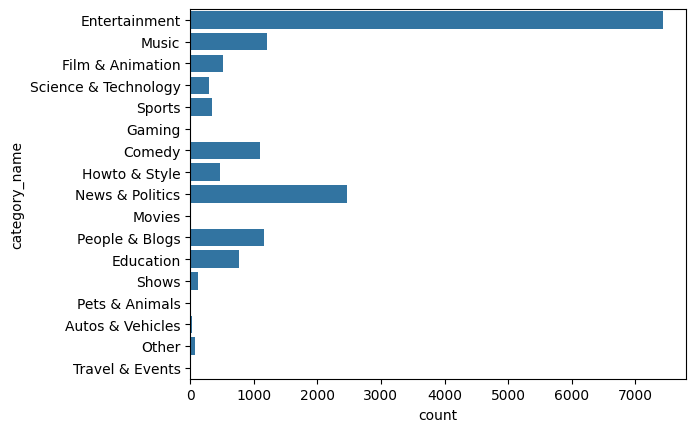

In [17]:
sns.countplot(df['category_name'])

<Axes: ylabel='count'>

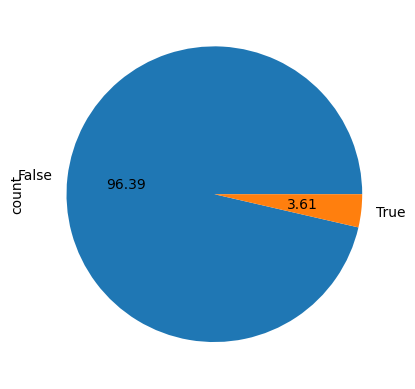

In [18]:
# comments_disabled
df['comments_disabled'].value_counts().plot(kind='pie',autopct='%.2f')

<Axes: ylabel='count'>

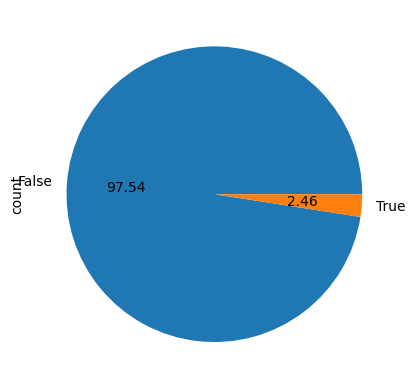

In [19]:
 #rating_disabled
df['ratings_disabled'].value_counts().plot(kind='pie',autopct='%.2f')

NUMERICAL DATA ANALYSIS

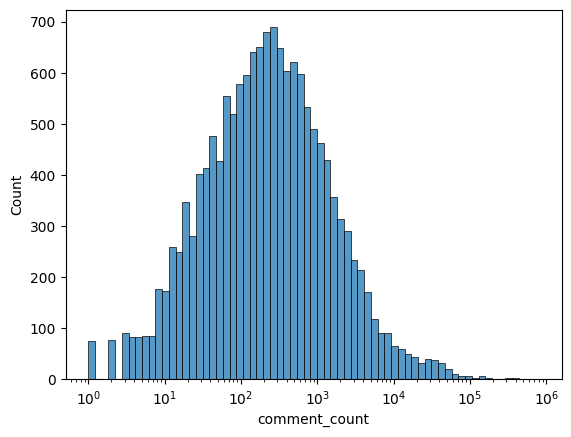

In [20]:
sns.histplot(df['comment_count'], log_scale=True)
plt.show()
# it is a little right skewed

APPLYING NORMAL ENCODING TO THE DATA 

In [21]:
from sklearn.preprocessing import FunctionTransformer
import numpy as np

# 1. Filter rows where comment_count is greater than 0
df = df[df["comment_count"] > 0]


In [22]:

# 2. Compute the log-transformed column
df["log_comment_count"] = np.log1p(df["comment_count"])

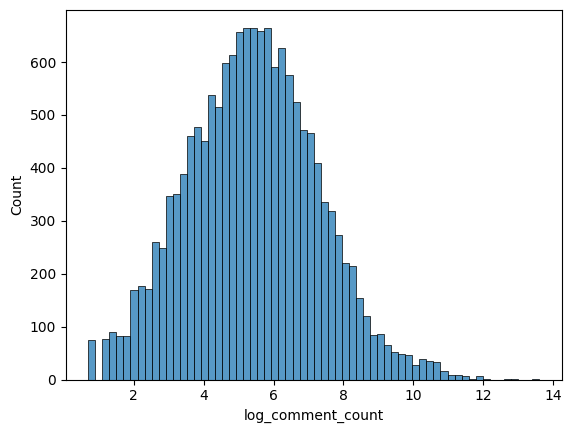

In [23]:
sns.histplot(df['log_comment_count'])
plt.show()
# it is a little right skewed

In [24]:
df["log_views"] = np.log1p(df["views"])
df["log_likes"] = np.log1p(df["likes"])
df["log_dislikes"] = np.log1p(df["dislikes"])
df["title_length"] = df["title"].astype(str).apply(len) 
df.head()

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,...,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name,log_comment_count,log_views,log_likes,log_dislikes,title_length
5408,FlsCjmMhFmw,17.12.12,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,24,2017-12-06 17:58:51+00:00,"Rewind|""Rewind 2017""|""youtube rewind 2017""|""#Y...",125432237,2912710,1545017,...,False,False,False,"YouTube Rewind 2017. Celebrating the videos, p...",Entertainment,13.601771,18.647276,14.884595,14.250546,50
4477,6ZfuNTqbHE8,17.07.12,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,24,2017-11-29 13:26:24+00:00,"marvel|""comics""|""comic books""|""nerdy""|""geeky""|...",89930713,2606663,53011,...,False,False,False,There was an ideaâ¦ Avengers: Infinity War. I...,Entertainment,12.759909,18.314550,14.773582,10.878274,55
29298,u9Mv98Gr5pY,18.01.05,VENOM - Official Trailer (HD),Sony Pictures Entertainment,24,2018-04-24 03:45:03+00:00,"Venom|""Venom Movie""|""Venom (2018)""|""Marvel""|""M...",53822757,1250535,44796,...,False,False,False,We Are #Venom. 10.5.18\n\nOne of Marvel's most...,Entertainment,11.816033,17.801207,14.039083,10.709896,29
22949,QwievZ1Tx-8,18.22.03,Marvel Studios' Avengers: Infinity War - Offic...,Marvel Entertainment,24,2018-03-16 13:02:41+00:00,"marvel|""comics""|""comic books""|""nerd""|""geek""|""s...",45064699,1494997,29812,...,False,False,False,In theaters April 27. Get your tickets now: ht...,Entertainment,12.133534,17.623610,14.217635,10.302700,57
29668,rRr1qiJRsXk,18.03.05,Sanju | Official Teaser | Ranbir Kapoor | Rajk...,FoxStarHindi,24,2018-04-24 07:58:08+00:00,"Sanju Teaser|""Official Teaser""|""Sanju Official...",44171797,780895,30791,...,False,False,False,Few lives in our times are as dramatic and eni...,Entertainment,10.775408,17.603597,13.568197,10.335010,57


In [25]:
from sklearn.model_selection import train_test_split
feature_cols=["log_likes","log_dislikes","log_comment_count","title_length","category_name"]
X=df[feature_cols]
y=df["log_views"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

<Axes: ylabel='log_likes'>

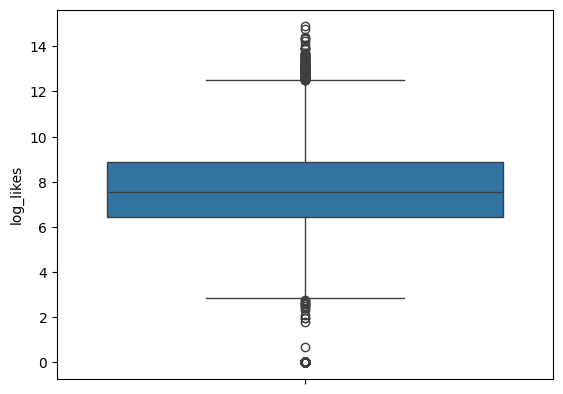

In [26]:
sns.boxplot(df["log_likes"])

<Axes: ylabel='log_dislikes'>

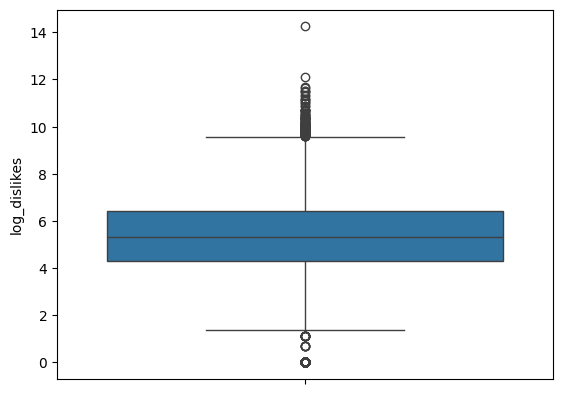

In [27]:
sns.boxplot(df["log_dislikes"])

<Axes: ylabel='log_views'>

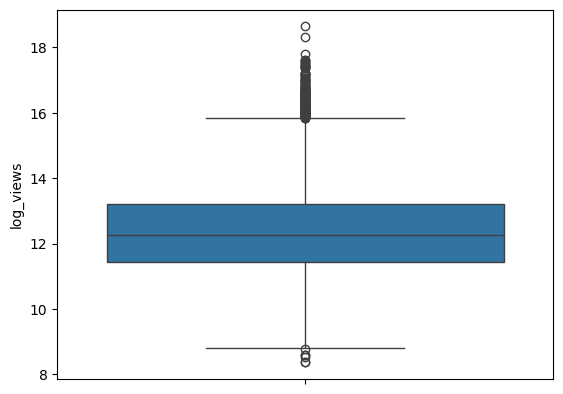

In [28]:
sns.boxplot(df["log_views"])

<Axes: ylabel='log_comment_count'>

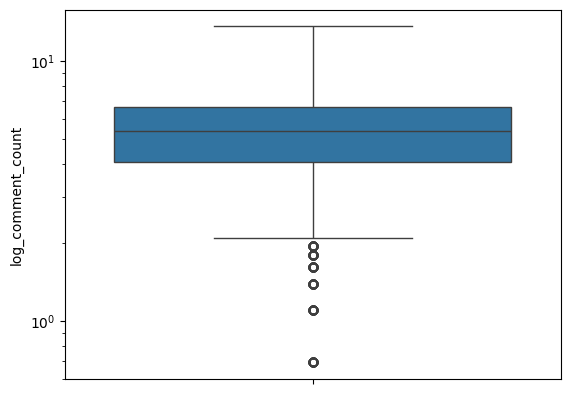

In [29]:
sns.boxplot(df["log_comment_count"],log_scale=True)

In [30]:
df.head()

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,...,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name,log_comment_count,log_views,log_likes,log_dislikes,title_length
5408,FlsCjmMhFmw,17.12.12,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,24,2017-12-06 17:58:51+00:00,"Rewind|""Rewind 2017""|""youtube rewind 2017""|""#Y...",125432237,2912710,1545017,...,False,False,False,"YouTube Rewind 2017. Celebrating the videos, p...",Entertainment,13.601771,18.647276,14.884595,14.250546,50
4477,6ZfuNTqbHE8,17.07.12,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,24,2017-11-29 13:26:24+00:00,"marvel|""comics""|""comic books""|""nerdy""|""geeky""|...",89930713,2606663,53011,...,False,False,False,There was an ideaâ¦ Avengers: Infinity War. I...,Entertainment,12.759909,18.314550,14.773582,10.878274,55
29298,u9Mv98Gr5pY,18.01.05,VENOM - Official Trailer (HD),Sony Pictures Entertainment,24,2018-04-24 03:45:03+00:00,"Venom|""Venom Movie""|""Venom (2018)""|""Marvel""|""M...",53822757,1250535,44796,...,False,False,False,We Are #Venom. 10.5.18\n\nOne of Marvel's most...,Entertainment,11.816033,17.801207,14.039083,10.709896,29
22949,QwievZ1Tx-8,18.22.03,Marvel Studios' Avengers: Infinity War - Offic...,Marvel Entertainment,24,2018-03-16 13:02:41+00:00,"marvel|""comics""|""comic books""|""nerd""|""geek""|""s...",45064699,1494997,29812,...,False,False,False,In theaters April 27. Get your tickets now: ht...,Entertainment,12.133534,17.623610,14.217635,10.302700,57
29668,rRr1qiJRsXk,18.03.05,Sanju | Official Teaser | Ranbir Kapoor | Rajk...,FoxStarHindi,24,2018-04-24 07:58:08+00:00,"Sanju Teaser|""Official Teaser""|""Sanju Official...",44171797,780895,30791,...,False,False,False,Few lives in our times are as dramatic and eni...,Entertainment,10.775408,17.603597,13.568197,10.335010,57


In [31]:
# Apply IQR ONLY to input features in X_train

feature_cols_to_clean = ["log_likes", "log_dislikes", "log_comment_count"]

for col in feature_cols_to_clean:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    valid_idx = X_train[
        (X_train[col] >= lower_bound) & (X_train[col] <= upper_bound)
    ].index

    X_train = X_train.loc[valid_idx]
    y_train = y_train.loc[valid_idx]

In [32]:
df.head()

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,...,comments_disabled,ratings_disabled,video_error_or_removed,description,category_name,log_comment_count,log_views,log_likes,log_dislikes,title_length
5408,FlsCjmMhFmw,17.12.12,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,24,2017-12-06 17:58:51+00:00,"Rewind|""Rewind 2017""|""youtube rewind 2017""|""#Y...",125432237,2912710,1545017,...,False,False,False,"YouTube Rewind 2017. Celebrating the videos, p...",Entertainment,13.601771,18.647276,14.884595,14.250546,50
4477,6ZfuNTqbHE8,17.07.12,Marvel Studios' Avengers: Infinity War Officia...,Marvel Entertainment,24,2017-11-29 13:26:24+00:00,"marvel|""comics""|""comic books""|""nerdy""|""geeky""|...",89930713,2606663,53011,...,False,False,False,There was an ideaâ¦ Avengers: Infinity War. I...,Entertainment,12.759909,18.314550,14.773582,10.878274,55
29298,u9Mv98Gr5pY,18.01.05,VENOM - Official Trailer (HD),Sony Pictures Entertainment,24,2018-04-24 03:45:03+00:00,"Venom|""Venom Movie""|""Venom (2018)""|""Marvel""|""M...",53822757,1250535,44796,...,False,False,False,We Are #Venom. 10.5.18\n\nOne of Marvel's most...,Entertainment,11.816033,17.801207,14.039083,10.709896,29
22949,QwievZ1Tx-8,18.22.03,Marvel Studios' Avengers: Infinity War - Offic...,Marvel Entertainment,24,2018-03-16 13:02:41+00:00,"marvel|""comics""|""comic books""|""nerd""|""geek""|""s...",45064699,1494997,29812,...,False,False,False,In theaters April 27. Get your tickets now: ht...,Entertainment,12.133534,17.623610,14.217635,10.302700,57
29668,rRr1qiJRsXk,18.03.05,Sanju | Official Teaser | Ranbir Kapoor | Rajk...,FoxStarHindi,24,2018-04-24 07:58:08+00:00,"Sanju Teaser|""Official Teaser""|""Sanju Official...",44171797,780895,30791,...,False,False,False,Few lives in our times are as dramatic and eni...,Entertainment,10.775408,17.603597,13.568197,10.335010,57


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

categorical_cols=["category_name"]
numerical_cols=["log_likes","log_dislikes","title_length"]
# This function deletes the first binary feature of the column and help's us to handle unkown data.
process_data = ColumnTransformer(
    transformers=[("num",StandardScaler(),numerical_cols),("cat",OneHotEncoder(drop="first",handle_unknown="ignore"),categorical_cols)]
)

In [34]:
X_train_processed = process_data.fit_transform(X_train)
X_test_processed = process_data.transform(X_test)

c:\Users\Prince Tandon\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


lr = LinearRegression()
lr.fit(X_train_processed, y_train)


y_pred_log = lr.predict(X_test_processed)


print("R2 Score (log scale):", r2_score(y_test, y_pred_log))
print("RMSE (log scale):", np.sqrt(mean_squared_error(y_test, y_pred_log)))


y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred_log)

R2 Score (log scale): 0.740612501140028
RMSE (log scale): 0.6782767534295571


In [36]:
from sklearn.model_selection import cross_val_score
mean_r2 = np.mean(cross_val_score(lr, X_train_processed, y_train, cv=5, scoring='r2'))

print("score is ", mean_r2)

score is  0.7759342483637394


In [ ]:
import numpy as np
import pandas as pd

# 1. Two new sample videos
new_videos = pd.DataFrame(
    [
        {
            "log_likes": np.log1p(45000),
            "log_dislikes": np.log1p(800),
            "log_comment_count": np.log1p(3200),
            "title_length": 45,
            "category_name": "Entertainment",
        },
        {
            "log_likes": np.log1p(2500),
            "log_dislikes": np.log1p(40),
            "log_comment_count": np.log1p(150),
            "title_length": 60,
            "category_name": "Education",
        },
    ]
)

# 2. Transform using your fitted preprocessor
new_data_processed = process_data.transform(new_videos)

pred_log = lr.predict(new_data_processed)
pred_views = np.expm1(pred_log)

# 4. Output results
print(f"Video 1 (Entertainment): {int(round(pred_views[0])):,} views")
print(f"Video 2 (Education):     {int(round(pred_views[1])):,} views")

Video 1 (Entertainment): 1,008,035 views
Video 2 (Education):     40,149 views
